<a href="https://colab.research.google.com/github/BeatrizCazatti/deep-learning/blob/main/2026_2_Practice_2_Implementing_LENET_5_architecture_using_Keras.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# *1 - Hands-on TensorFlow + Keras + LENET-5*

Implement and train several times using keras API your own LENET-5 implementation. The network should be trained to classify the images of the MNIST dataset.

## *1.1 - Load tensor flow*

In [ ]:
import tensorflow as tf

## *1.2 - Dataset preparation*

### *Import and prepare dataset*

Modified NIST (MNIST) is a database of handwritten digits. It encompasses a training set of 60,000 examples, and a test set of 10,000 examples. Images available in keras library are 28x28x1-sized.

The final part of the following code normalizes the training data to [0,1].

In [ ]:
mnist = tf.keras.datasets.mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()
print ("Training set info:",x_train.shape)
print ("Train target info:",y_train.shape)
print ("Test set info:",x_test.shape)
print ("Test target info:",y_test.shape)

x_train_norm, x_test_norm = x_train / 255.0, x_test / 255.0

### *Show sample images*


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 7))
for i in range(100,200):
  ax = plt.subplot(10, 10, i-99)
  plt.axis("off")
  plt.imshow(x_train_norm[i],interpolation='bilinear', cmap='gray')

### *1.3 - Create and Initialize LENET-5 Architecture*

Just as an example, the code bellow implements a single-hidden-layer perceptron using Keras functional architecture.



In [ ]:
# Here goes a functional implementation of a MLP:
def mymlp_functional( hidd_neu = 128, hidd_act='relu',do_freq=0.2):
  inputs = tf.keras.layers.Input(shape=(28,28))
  x = tf.keras.layers.Flatten(input_shape=(28, 28))(inputs)
  x = tf.keras.layers.Dense(hidd_neu, activation=hidd_act) (x)
  x = tf.keras.layers.Dropout(do_freq) (x)
  outputs = tf.keras.layers.Dense(10, activation='softmax') (x)
  return tf.keras.models.Model(inputs, outputs, name='mymlp')


**Task 1** Implement using the Keras functional API the  [LENET-5 architecture](http://vision.stanford.edu/cs598_spring07/papers/Lecun98.pdf).

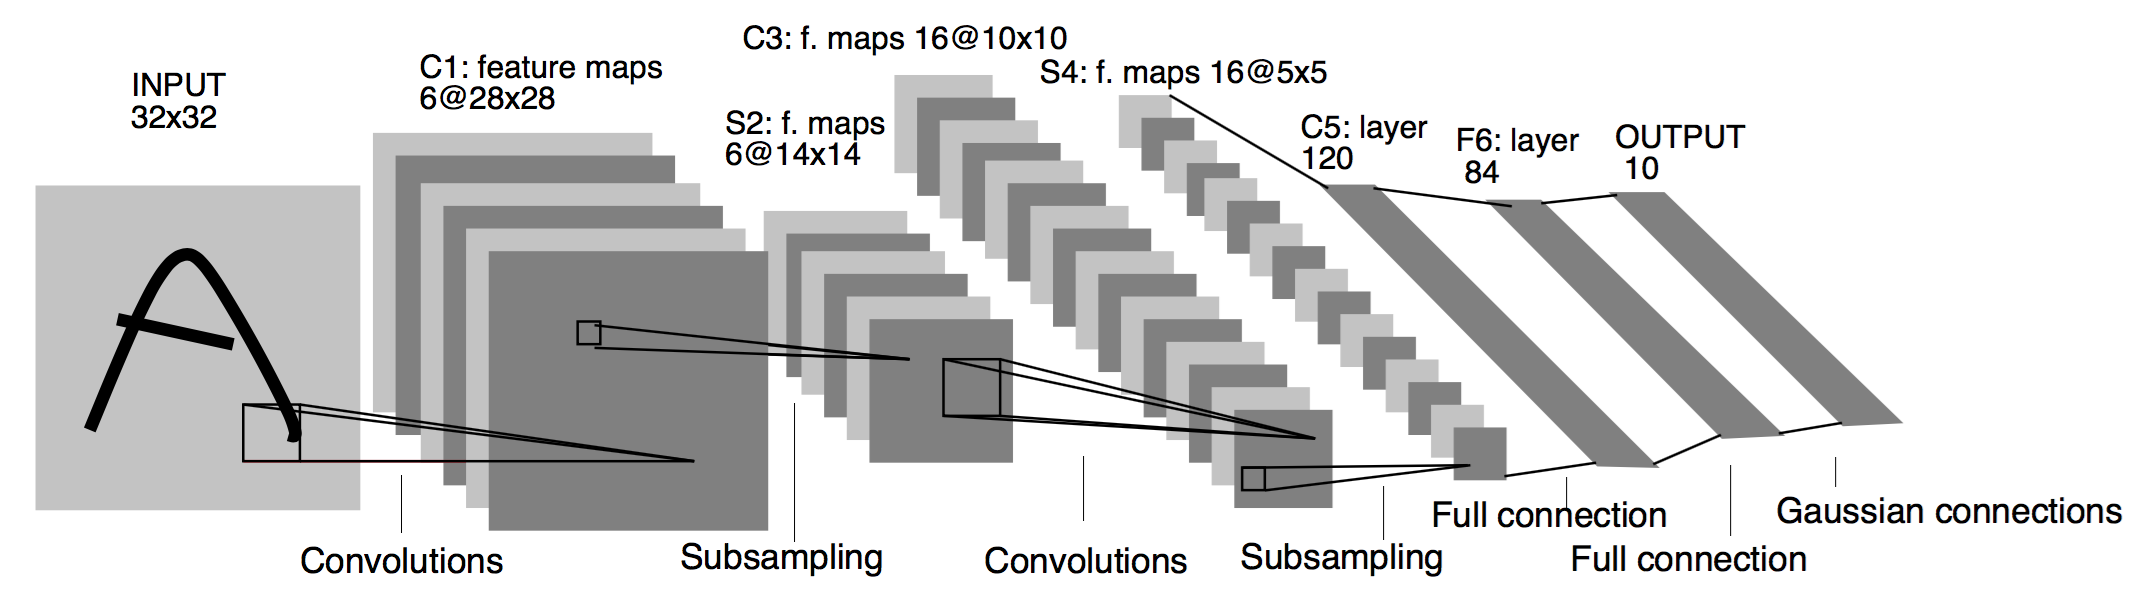

Here we will do the following modifications on the original LENET arquitecture:
* The input will be a 28 x 28 (MNIST) image.
* The first convolutional layer will produce feature maps with the same width and hight of the input images (use padding).
* All convolutional layers (tf.keras.layers.Conv2D(...)) should have RELU activation.
* All but the last fully conected layers should also have RELU activations. The output layer should have softmax activation.
* The subsampling operations should be implemented through MaxPooling (with filter size 2x2 and stride 2).
* We will drop the C5 layer, and substitute it by a MaxPooling followed by a flattening operation.

For the 2D-convolutional and maxpooling layers use the Keras functions [Conv2D](https://keras.io/api/layers/convolution_layers/convolution2d/) and [MaxPool2D](https://keras.io/api/layers/pooling_layers/max_pooling2d/), respectfully.

In addition, incorporate [batch normalization](https://keras.io/api/layers/normalization_layers/batch_normalization/) and dropout (after the fully conected layers) to your implementation.

For further information, consult [Keras layers API ](https://keras.io/api/layers/).

In [ ]:
#Use this space to answer Task 1

**Task 2** Calculate the number of parameters of the above model. Compare the estimatad values to the one provided by Model.summary().


In [ ]:
#Use this space to answer Task 2

Model: "my_lenet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 120)      │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1080)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 84)             │        90,804 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 84)             │           336 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 84)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 84)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           850 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 10)             │            40 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 142,722 (557.51 KB)

 Trainable params: 142,534 (556.77 KB)

 Non-trainable params: 188 (752.00 B)

##*1.4 - Network training*

Remember the training process workflow:
1. Architecture setup
2. Network instantiation
3. Parameters initialization.
4. Training graph setup
5. Paramenters optimization
6. Evaluation

Details can be found in the [keras documentation](https://keras.io/api/models/model_training_apis/).

**Task 3**: Train the model for 50 epochs, using the Adam optimizer.

In [ ]:
# Put you code for Task 3 here

**Task 4**: Analyse the training history graph. In your opinion, which was the "best" epoch? Why?

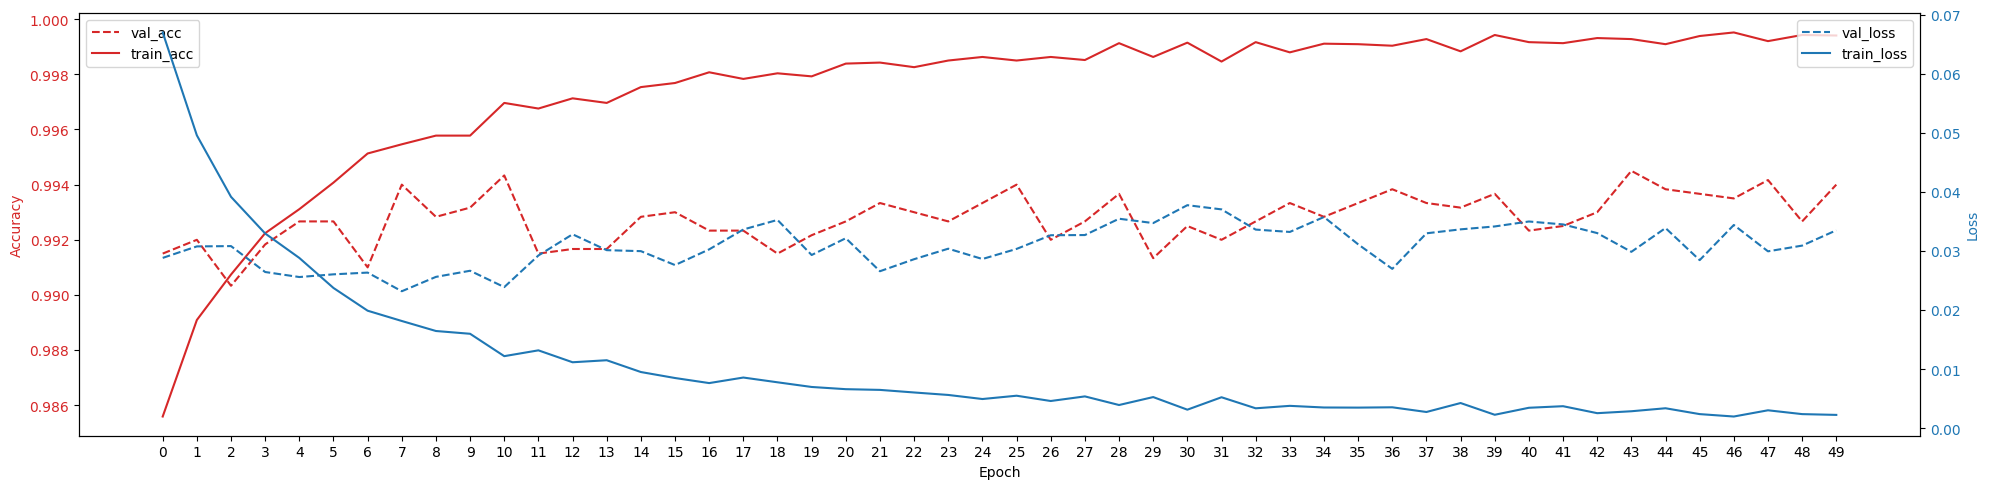

In [ ]:
import numpy as np

fig, ax1 = plt.subplots(figsize=(20, 5))

color = 'tab:red'
ax1.set_xlabel('Epoch')
ax1.set_xticks(np.arange(EPOCHS))
ax1.set_ylabel('Accuracy', color=color)
ax1.plot(H.history["val_accuracy"], '--', label="val_acc", color=color)
ax1.plot(H.history["accuracy"], label="train_acc", color=color)
ax1.tick_params(axis='y', labelcolor=color)
ax1.legend()

ax2 = ax1.twinx()  # instantiate a second axes that shares the same x-axis

color = 'tab:blue'
ax2.set_ylabel('Loss', color=color)  # we already handled the x-label with ax1
ax2.plot(H.history["val_loss"], '--', label="val_loss", color=color)
ax2.plot(H.history["loss"], label="train_loss",color=color)
ax2.tick_params(axis='y', labelcolor=color)
ax2.legend()

fig.tight_layout()  # otherwise the right y-label is slightly clipped
plt.show()

**Task 5**: Remove the Batch Normalization and Dropout layers from the architecture and train the network again for 50 epochs, using the Adam optimizer.

In [ ]:
#Put your code for Task 5 here

**Task 6**: Analyse the training history graph. In your opinion, which was the "best" epoch now? Why?

In [ ]:
#Put your code for Task 6 here

**Task 7**: Train the network implemented in Task 1 with the [Early Stopping callback](https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/EarlyStopping). The patience parameter should be 5 epochs. Use a number of epochs so that the best epoch is not the last one.

In [ ]:
#Put your code for Task 7 here

# This is only the callback function
es_callback = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    min_delta=0,
    patience=5,
    verbose=0,
    mode='auto',
    baseline=None,
    restore_best_weights=False,
    start_from_epoch=0
)


**Task 8**: Analyse the training history graph. Which was the "best" epoch?

In [ ]:
#Put your code for Task 8 here

##*2 - Rigorous evaluation*
Tasks 9 to 15 will introduce yourself to a more thorought evaluation of the network trained in **Task 7**. It is a really important need for ensuring network quality.

**Task 9**: Obtain the test set [confusion matrix](https://gsp.humboldt.edu/olm/Courses/GSP_216/lessons/accuracy/metrics.html) for the above trained network. Consider using the confusion_matrix and ConfusionMatrixDisplay from the Scikit Learn library.



313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


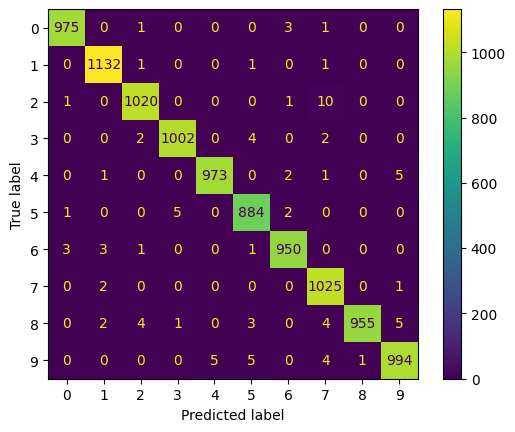

In [ ]:
#Put your code for Task 9 here

**Task 10**: Present the [overall accuracy](https://gsp.humboldt.edu/olm/Courses/GSP_216/lessons/accuracy/metrics.html).

In [ ]:
#Put your code for Task 10 here

**Task 11**: Present the [errors of omission and commission](https://gsp.humboldt.edu/olm/Courses/GSP_216/lessons/accuracy/metrics.html).

In [ ]:
#Put your code for Task 11 here

**Task 12**: Present [user's  and producer's accuracy](https://gsp.humboldt.edu/olm/Courses/GSP_216/lessons/accuracy/metrics.html).

In [ ]:
#Put your code for Task 12 here

**Task 13**: Obtain the [Kappa](https://gsp.humboldt.edu/olm/Courses/GSP_216/lessons/accuracy/metrics.html) value.

In [ ]:
#Put your code for Task 13 here

##*3 - Optimizers*

Evaluate the impact of optimizer's choice during training process.


**Task 14**: Train the network implemented in Task 7 (with early stopping) varying the [optimizers](https://keras.io/api/optimizers/#available-optimizers). Save the training history for each training, then plot histories of both losses and accuracies in the training set. Also compare the training and test final accuracy values obtained using each optimizer.  

Click here for [tf.keras.optimizers](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers) documentation. There you may find the following variants:

  * SGD
  * RMSprop
  * Adam
  * Adadelta
  * Adagrad




In [ ]:
# Put your code here for Task 14

**Task 15** Put your outcomes here in the form of a table. The table should show the best epoch and the overall accuracy obtained on the test data, for each optimizer.